# FFT-ресемплинг: исследование реальных сигналов · перенос в COS1 0.2.0

**Цель:** понять изменение временной сетки, спектра и статистик при переходе к 51 200 Гц. Здесь выполняются отдельные шаги, без `run("all")`. Вычисления используют пакет `cos1`, установленный через `pip install -e ".[dev]"` в выбранный kernel.

Исходные данные: 14 секундных фрагментов пяти наборов и три канала полной записи HUSTbearing. Это 17 рядов, но не 17 независимых опытов. Notebook ничего не перезаписывает в исходных или обработанных данных. Run All можно повторять.

Этот Notebook совместим с неизменённым пакетом версии 0.2.0; обновление пакета и пересоздание окружения не требуются.

## Как читать исследование

Вибрационный временной ряд — последовательность показаний датчика $x_n$. Один отсчёт — одно число в момент $t_n=n/f_s$. Частота дискретизации $f_s$ показывает число отсчётов в секунду; это не частота вращения и не частота дефекта.

$$T=N/f_s,\qquad M=T f_s',\qquad \Delta t=1/f_s,\qquad f_N=f_s/2.$$

$T$ — длительность периодического блока; $M$ — длина новой сетки. Шаг $\Delta t$ задаёт расстояние между соседними моментами. Найквист $f_N$ — верхняя граница представления частот без неоднозначности при выполнении условий дискретизации, а не гарантия полезной полосы датчика.

Единая сетка упрощает последующие операции с временными интервалами и частотными осями. 51 200 Гц выбраны по заданию преподавателя; оптимальность этой частоты для диагностики здесь не устанавливается. Она не уравнивает обороты, калибровки и исходные информационные полосы.

FFT раскладывает конечную запись на гармоники периодической модели. При повышении добавляются нулевые высокочастотные коэффициенты и вычисляются промежуточные значения на новой сетке. При понижении недоступные частоты отбрасываются. Фазы сохраняемых гармоник важны. Соединение конца записи с началом может создавать краевые колебания; новые значения между отсчётами — результат модели, не физические измерения.


In [1]:
from io import BytesIO
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from cos1.data import ROOT, records, load
from cos1.time_grid import plan
from cos1.resampling import transform
from cos1.spectrum import amplitude_spectrum
from cos1.analysis import statistics, check

print("COS1", version("cos1"), "| проект:", ROOT)
rows = records()
by_id = {row["id"]: row for row in rows}
display(pd.DataFrame(rows)[["id", "dataset", "source_filename", "channel", "original_sample_rate_hz", "n_samples_available"]])

def show(fig):
    # Явное отображение PNG работает и с интерактивным, и с Agg backend.
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11})


COS1 0.2.0 | проект: /workspace/scratch/a5124278568b/tmp/update_base_0.2.0/COS1


,id,dataset,source_filename,channel,original_sample_rate_hz,n_samples_available
0,cwru_normal,CWRU,97.mat,X097_DE_time,48000,48000
1,cwru_inner,CWRU,105.mat,X105_DE_time,12000,12000
2,cwru_ball,CWRU,118.mat,X118_DE_time,12000,12000
3,cwru_outer,CWRU,130.mat,X130_DE_time,12000,12000
4,pu_K001,Paderborn,N15_M07_F10_K001_1.mat,Y.vibration_1,64000,64000
5,pu_KA01,Paderborn,N15_M07_F10_KA01_1.mat,Y.vibration_1,64000,64000
6,jnu_normal,JNU,n600_3_2.csv,single vertical channel,50000,50000
7,jnu_inner,JNU,ib600_2.csv,single vertical channel,50000,50000
8,jnu_outer,JNU,ob600_2.csv,single vertical channel,50000,50000
9,jnu_ball,JNU,tb600_2.csv,single vertical channel,50000,50000


## 1. Математическая модель

Блок из $N$ отсчётов при частоте $f_s$ имеет длительность $T=N/f_s$. Интервал между первым и последним отсчётами равен $(N-1)/f_s$ — это другая величина. Новая длина $M=T f_{\mathrm{target}}$ должна быть целой.

ДПФ представляет периодическое продолжение блока. Для обычных парных частот коэффициенты сохраняются, высокочастотные коэффициенты дополняются нулями при повышении или отбрасываются при понижении. Обратное преобразование учитывает масштаб $M/N$; особый бин Найквиста обрабатывает SciPy. Фазы необходимы: модуль спектра не может заменить исходный сигнал.

Вызов использует `float64`, `axis=0`, `domain="time"`, `window=None`. Вход не нормируется и не умножается на окно. Повышение частоты означает интерполяцию периодической модели, а не новые измерения.

## 2. Выбираем сигнал
Начнём с CWRU 130.mat — дефект наружного кольца, исходные 12 кГц. Можно изменить `selected_id` на любое значение таблицы и повторить следующие ячейки. Физическое состояние берётся из манифеста, а не определяется по картинке.

In [2]:
selected_id = "cwru_outer"
row = by_id[selected_id]
x = load(row)
fs = int(row["original_sample_rate_hz"])
unit = row["signal_unit"] or "исходные единицы, калибровка не подтверждена"
print(row["source_filename"], row["fault_type"], x.dtype, x.shape)
assert np.isfinite(x).all()
t = np.arange(len(x)) / fs

130.mat outer race at 6 oclock float64 (12000,)


## 3. Исходная осциллограмма
Показываем первые 50 мс. Ось амплитуды сохраняет исходный масштаб; одинаковая частота дискретизации не делает единицы разных стендов сопоставимыми.

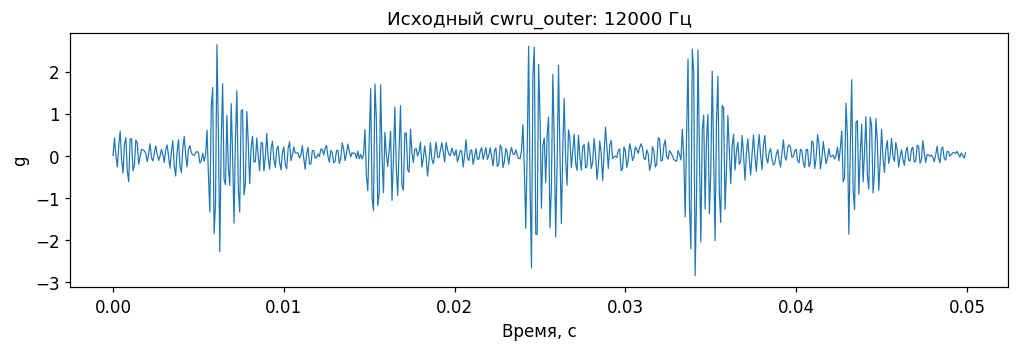

In [3]:
fig, ax = plt.subplots(figsize=(11, 3))
mask = t < 0.05
ax.plot(t[mask], x[mask], lw=0.8)
ax.set(xlabel="Время, с", ylabel=unit, title=f"Исходный {selected_id}: {fs} Гц")
show(fig)

## 4. Планируем сетки до преобразования
Планировщик не округляет дробное M молча. В текущем пилоте все размеры целые; для других записей нужна отдельная политика длительности.

In [4]:
grid = plan(len(x), fs, 51200)
t_new = np.arange(grid["M"]) / grid["fs_out"]
display(pd.DataFrame([
    {"сетка": "исходная", "N": len(x), "fs": fs, "T": len(x)/fs, "последний отсчёт": t[-1]},
    {"сетка": "новая", "N": grid["M"], "fs": grid["fs_out"], "T": grid["duration"], "последний отсчёт": t_new[-1]},
]))
assert len(t_new) == grid["M"]
assert np.allclose(np.diff(t_new), 1/grid["fs_out"])

,сетка,N,fs,T,последний отсчёт
0,исходная,12000,12000,1.0,0.999917
1,новая,51200,51200,1.0,0.999980


## 5. Выполняем ресемплинг
Это непосредственный вызов единственной реализации из пакета. Сохранённый NPY здесь не читается: результат вычисляется заново.

In [5]:
y, actual_grid = transform(x, fs, 51200)
assert actual_grid == grid
print("Получено", len(y), "отсчётов; длительность", len(y)/grid["fs_out"], "с")

Получено 51200 отсчётов; длительность 1.0 с


## 6. Общий интервал и увеличенная сетка
На первом графике видна форма сигнала, на втором — расположение отсчётов. Линии соединяют точки для удобства просмотра; они не обозначают дополнительное измерение.

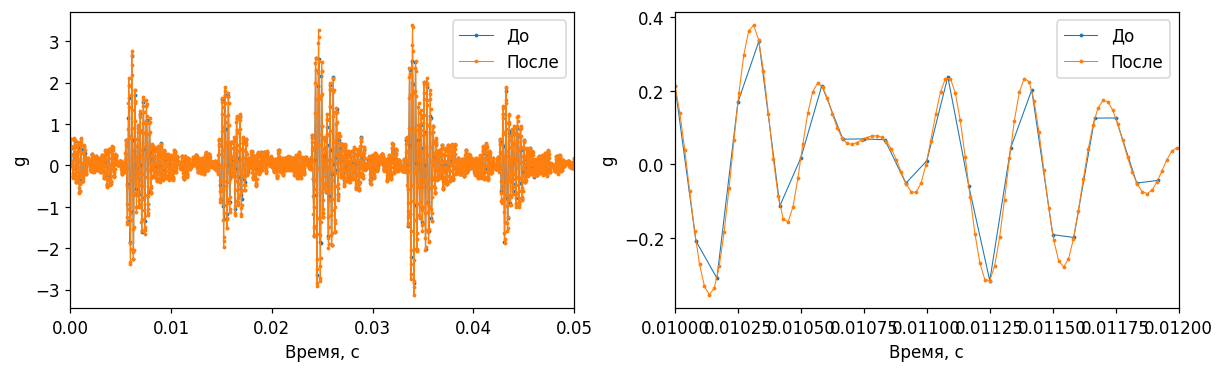

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for ax, limits in zip(axes, [(0, 0.05), (0.01, 0.012)]):
    for times, values, label in [(t, x, "До"), (t_new, y, "После")]:
        mask = (times >= limits[0]) & (times < limits[1])
        ax.plot(times[mask], values[mask], ".-", ms=3, lw=0.7, label=label)
    ax.set(xlabel="Время, с", ylabel=unit, xlim=limits)
    ax.legend()
show(fig)

## 7. Сравниваем спектры

Общая функция `amplitude_spectrum` удаляет среднее **только при расчёте спектра**, делит модуль ДПФ на сумму окна и удваивает парные положительные частоты. DC и Найквист не удваиваются. Для строгого сравнения коэффициентов используем прямоугольное окно; Ханн полезен для визуализации утечки, но меняет спектральную оценку.

У CWRU 12 кГц информационная граница не выше 6 кГц. Новая граница Найквиста 25,6 кГц не означает появления измерений в диапазоне 6–25,6 кГц.

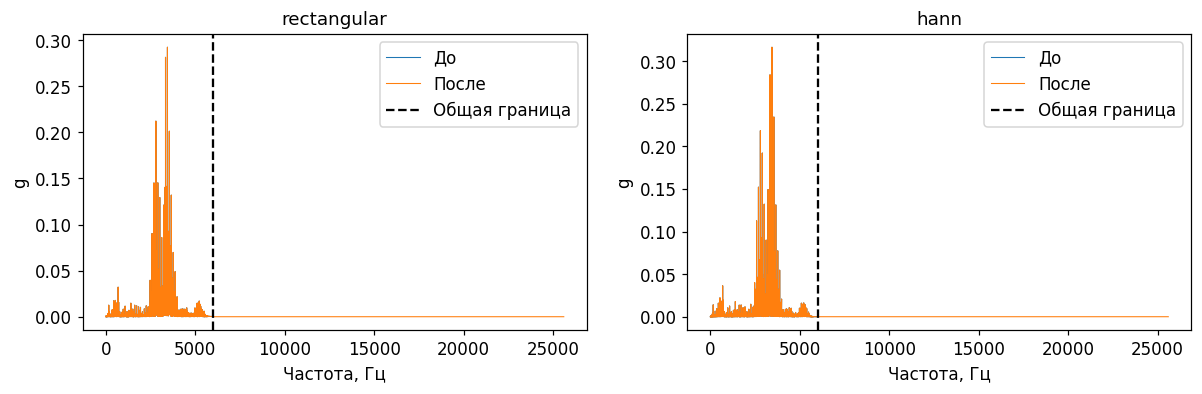

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for ax, window in zip(axes, ["rectangular", "hann"]):
    for values, rate, label in [(x, fs, "До"), (y, grid["fs_out"], "После")]:
        frequency, amplitude = amplitude_spectrum(values, rate, window)
        ax.plot(frequency, amplitude, lw=0.7, label=label)
    ax.axvline(min(fs, grid["fs_out"])/2, color="black", ls="--", label="Общая граница")
    ax.set(xlabel="Частота, Гц", ylabel=unit, title=window)
    ax.legend()
show(fig)

## 8. Численные критерии
Среднее и комплексные коэффициенты внутренней общей полосы должны сохраняться с численной погрешностью. Общая граничная частота исключена из этой метрики и проверяется отдельными тестами Найквиста. Длительность проверяем отдельно. Не требуем неизменности RMS и экстремумов.

In [8]:
validation = check(x, y, grid)
assert validation["passed"]
assert len(y)/grid["fs_out"] == len(x)/fs
assert np.isfinite(y).all()
display(pd.Series({key: validation[key] for key in [
    "mean_relative_error", "common_complex_error", "new_high_frequency_error",
    "duration_error_s", "input_energy_above_output_nyquist_fraction"]}))

mean_relative_error                           0.000000e+00
common_complex_error                          6.185256e-18
new_high_frequency_error                      5.161335e-18
duration_error_s                              0.000000e+00
input_energy_above_output_nyquist_fraction    0.000000e+00
dtype: float64

## 9. Статистики и их смысл

$\mu=\mathrm{mean}(x)$; $\mathrm{RMS}_{raw}=\sqrt{\mathrm{mean}(x^2)}$; $\sigma=\sqrt{\mathrm{mean}((x-\mu)^2)}$, делитель $N$.

$CF_{raw}=\max|x|/\mathrm{RMS}_{raw}$, $CF_c=\max|x-\mu|/\sigma$, эксцесс $=\mathrm{mean}((x-\mu)^4)/\sigma^4-3$. В пособии RMS центрирован; в проекте это отдельно подписанное СКО. После изменения сетки максимум может измениться даже при корректной интерполяции.

In [9]:
stats = pd.DataFrame({"До": statistics(x), "После": statistics(y)})
stats["Разность"] = stats["После"] - stats["До"]
display(stats)

,До,После,Разность
mean,0.033721,0.033721,0.000000e+00
rms_raw,0.676408,0.676408,-8.498821e-09
std_centered,0.675567,0.675567,-8.509402e-09
max_abs,3.547583,3.526876,-2.070705e-02
crest_raw,5.244740,5.214127,-3.061319e-02
crest_centered,5.201354,5.170703,-3.065130e-02
excess,4.620691,4.649901,2.920955e-02


## 10. Все пять наборов: повышение и понижение
В следующей ячейке каждый вход загружается и преобразуется заново. Все 17 результатов сравниваются с сохранёнными массивами 0.2.0. Временные массивы остаются в памяти; эталонные файлы не перезаписываются.

Сравнение с сохранёнными NPY использует допуск rtol=atol=1e−12 для различий округления FFT между платформами. Эталонные файлы не изменяются.

In [10]:
computed = {}
summary_rows = []
for item in rows:
    original = load(item)
    converted, item_grid = transform(original, int(item["original_sample_rate_hz"]))
    result = check(original, converted, item_grid)
    saved = np.load(ROOT/"data/processed"/(item["id"]+".npy"), allow_pickle=False)
    np.testing.assert_allclose(converted, saved, rtol=1e-12, atol=1e-12, err_msg=item["id"])
    assert result["passed"], item["id"]
    computed[item["id"]] = (original, converted, item_grid)
    summary_rows.append({"id": item["id"], "dataset": item["dataset"],
                         "fs_in": item_grid["fs_in"], "N": len(original), "M": len(converted),
                         "T": item_grid["duration"], **result})
summary = pd.DataFrame(summary_rows)
print("Проверено рядов:", len(summary))

Проверено рядов: 17


## 11. Пять характерных примеров
CWRU: 12→51,2 кГц; Paderborn: 64→51,2; MFPT: 97,656→51,2; JNU: 50→51,2; HUSTbearing: 25,6→51,2. Спектры рассчитаны по полному выбранному ряду, а не по отображаемым 20 мс. Масштабы разных стендов не сравниваются как физически одинаковые.

Повышение 12 → 51,2 кГц: сетка плотнее, но информация выше 6 кГц не появляется.
Понижение 64 → 51,2 кГц: коэффициенты выше 25,6 кГц удаляются; RMS может уменьшиться.
Понижение 97,656 → 51,2 кГц: удаляется верхняя часть исходной полосы до 48,828 кГц.
Повышение 50 → 51,2 кГц невелико: положения отсчётов меняются, измеренная полоса не расширяется.
Повышение 25,6 → 51,2 кГц вдвое: интерполяция между исходными отсчётами; информационная граница 12,8 кГц.


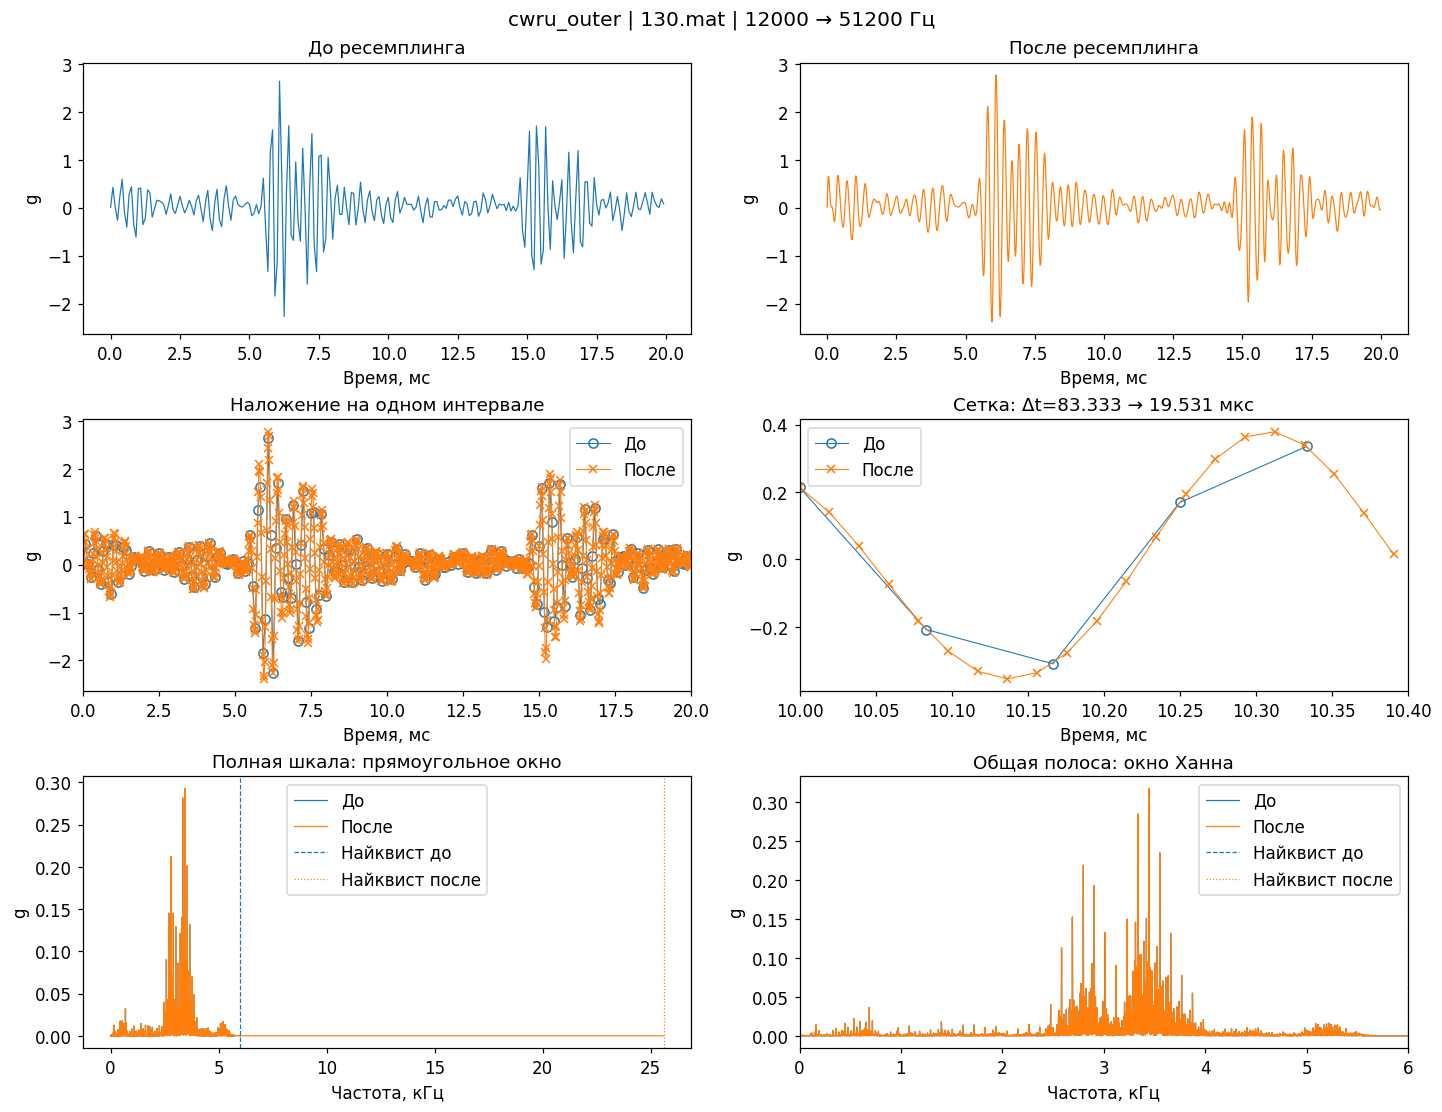

,До,После
mean,0.033721,0.033721
rms_raw,0.676408,0.676408
std_centered,0.675567,0.675567
max_abs,3.547583,3.526876
crest_raw,5.244740,5.214127
crest_centered,5.201354,5.170703
excess,4.620691,4.649901


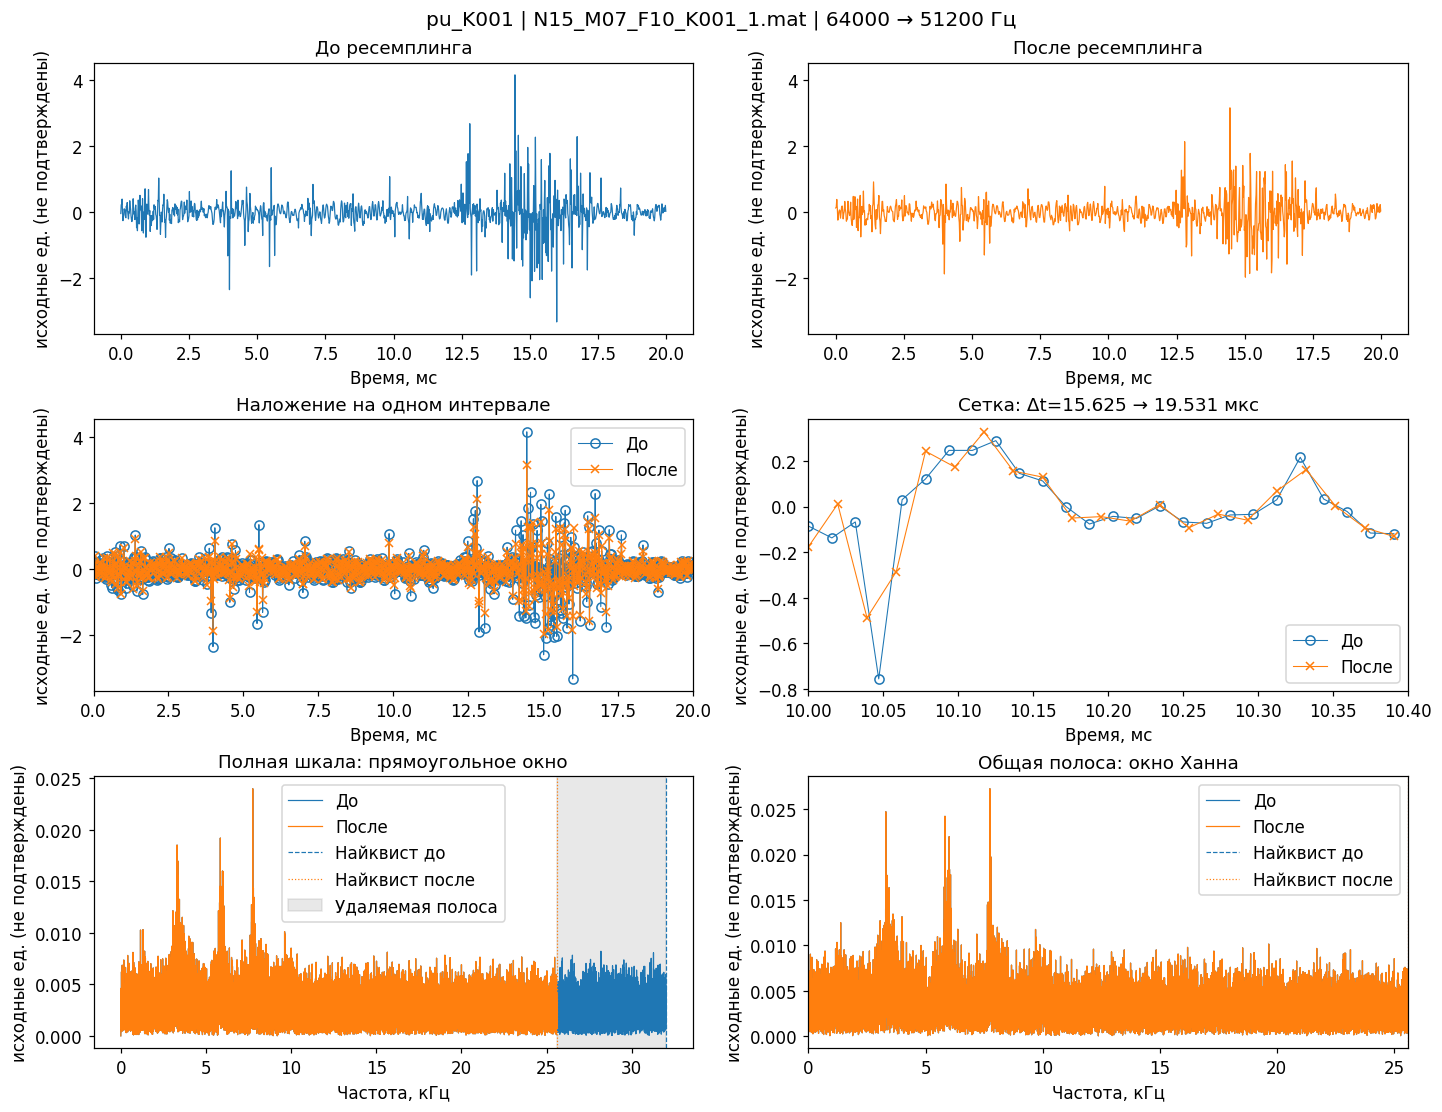

,До,После
mean,-0.018313,-0.018313
rms_raw,0.401837,0.367939
std_centered,0.401419,0.367483
max_abs,4.162598,3.161583
crest_raw,10.358927,8.592686
crest_centered,10.415322,8.653183
excess,10.345079,5.091856


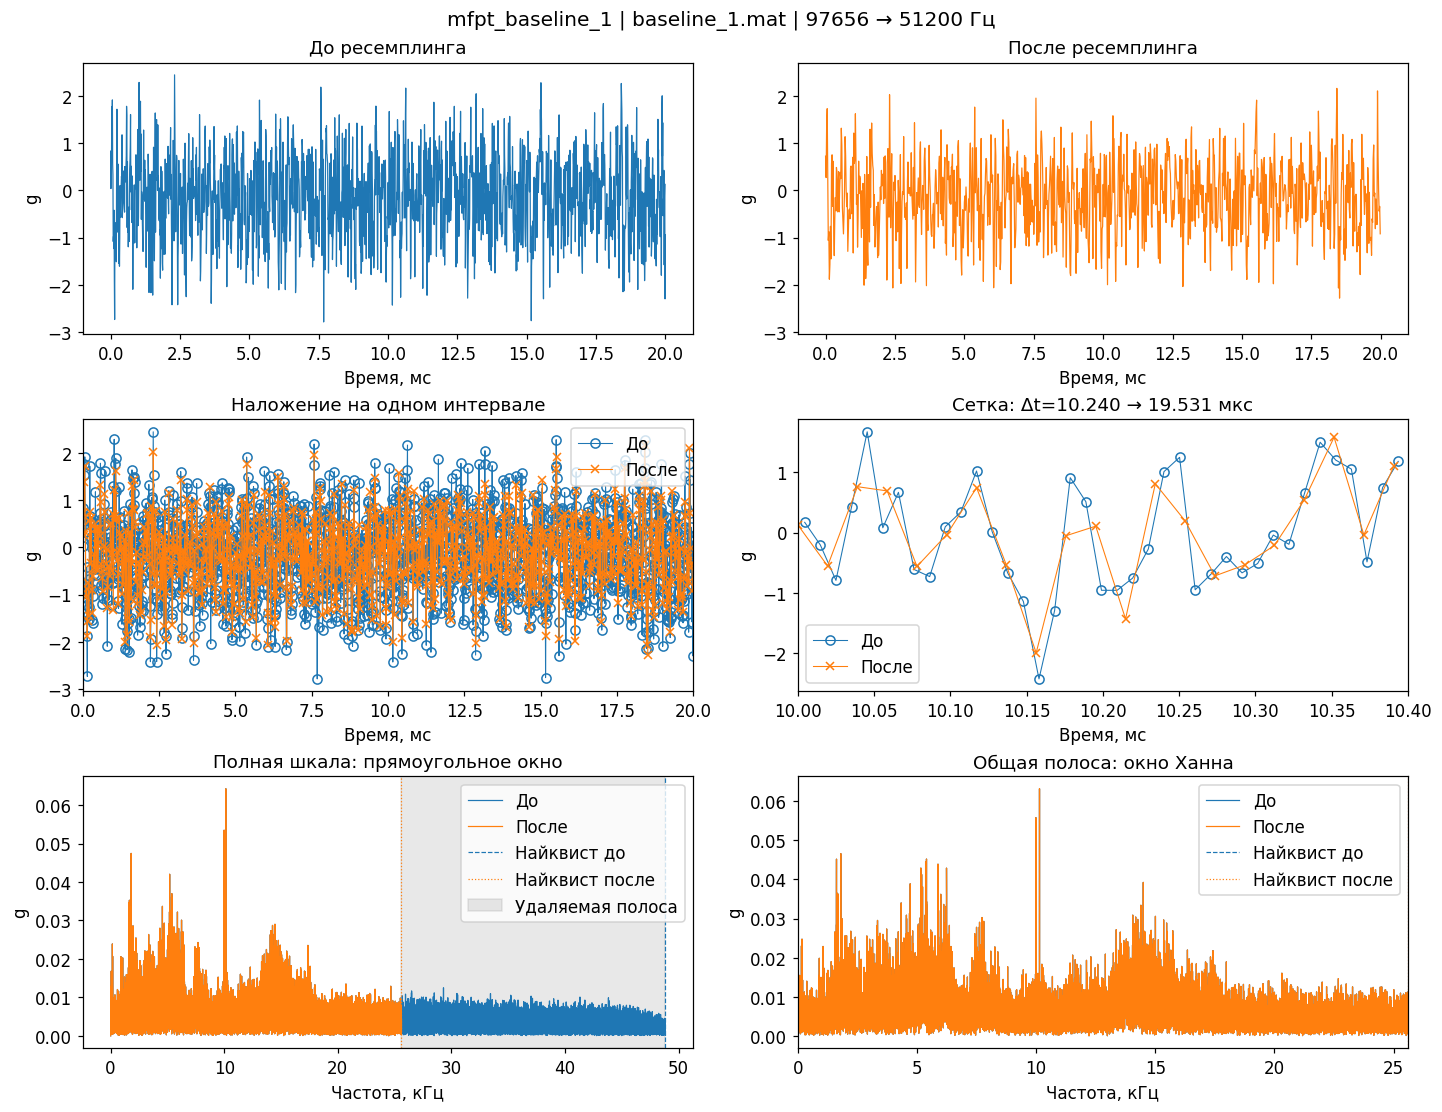

,До,После
mean,-0.136671,-0.136671
rms_raw,0.887210,0.795165
std_centered,0.876620,0.783331
max_abs,4.110280,3.179494
crest_raw,4.632814,3.998535
crest_centered,4.532874,4.212315
excess,0.033662,0.042263


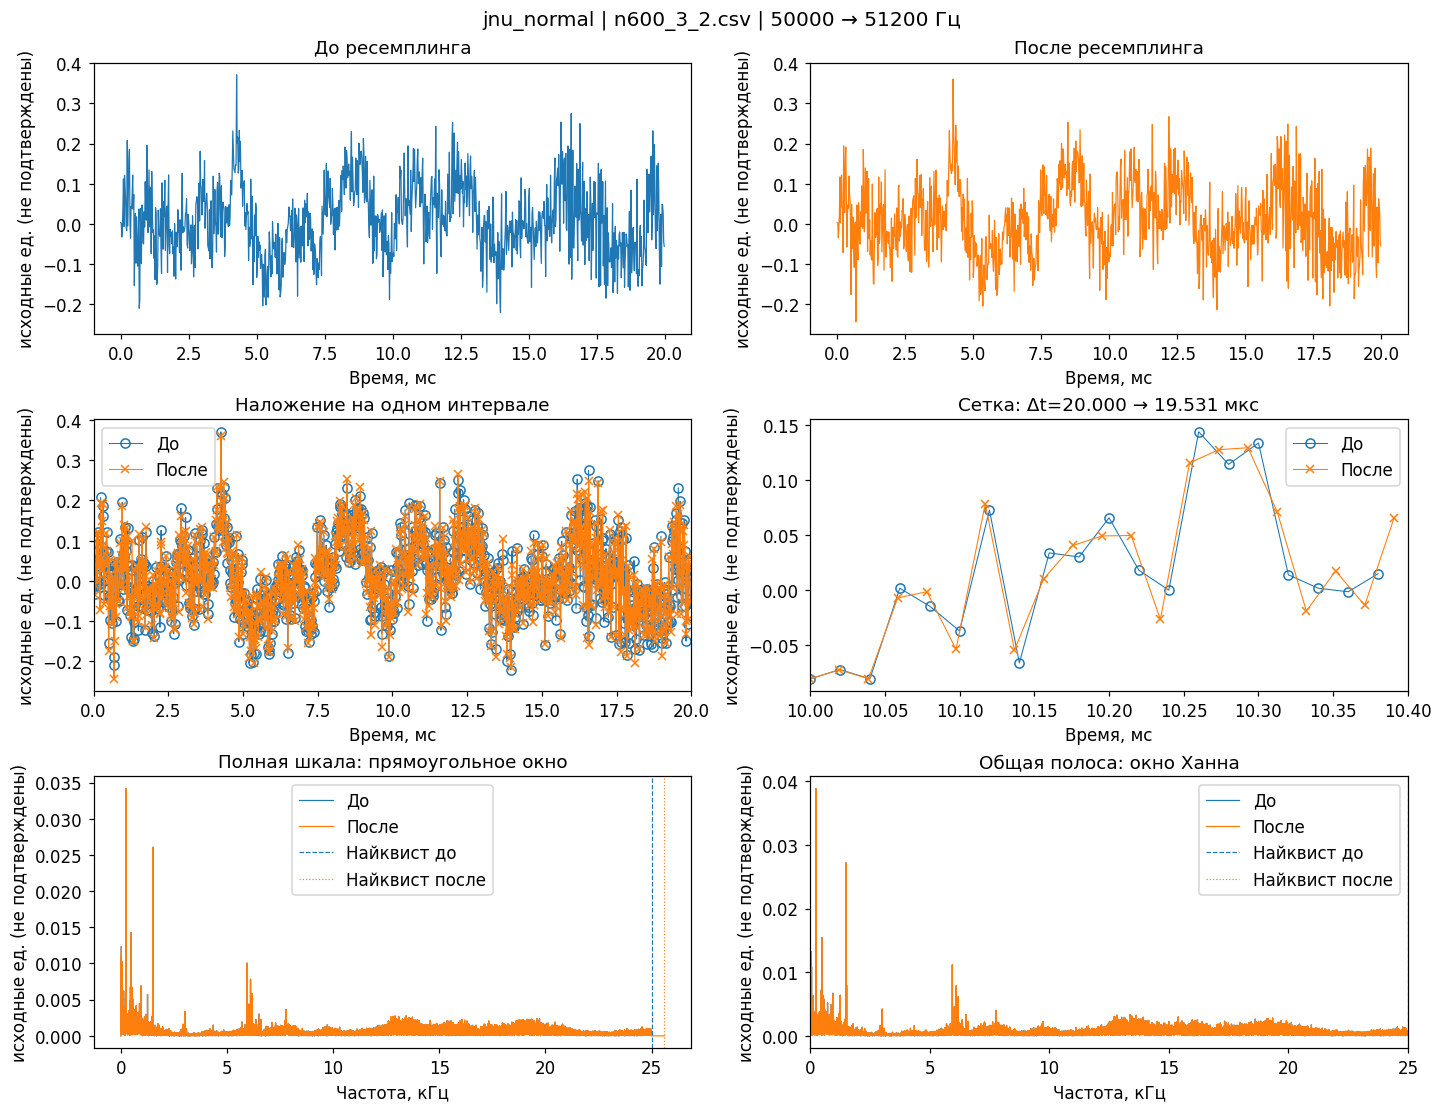

,До,После
mean,-0.001225,-0.001225
rms_raw,0.089459,0.089458
std_centered,0.089450,0.089450
max_abs,1.254500,1.496815
crest_raw,14.023262,16.731954
crest_centered,14.010884,16.747214
excess,7.930212,8.406451


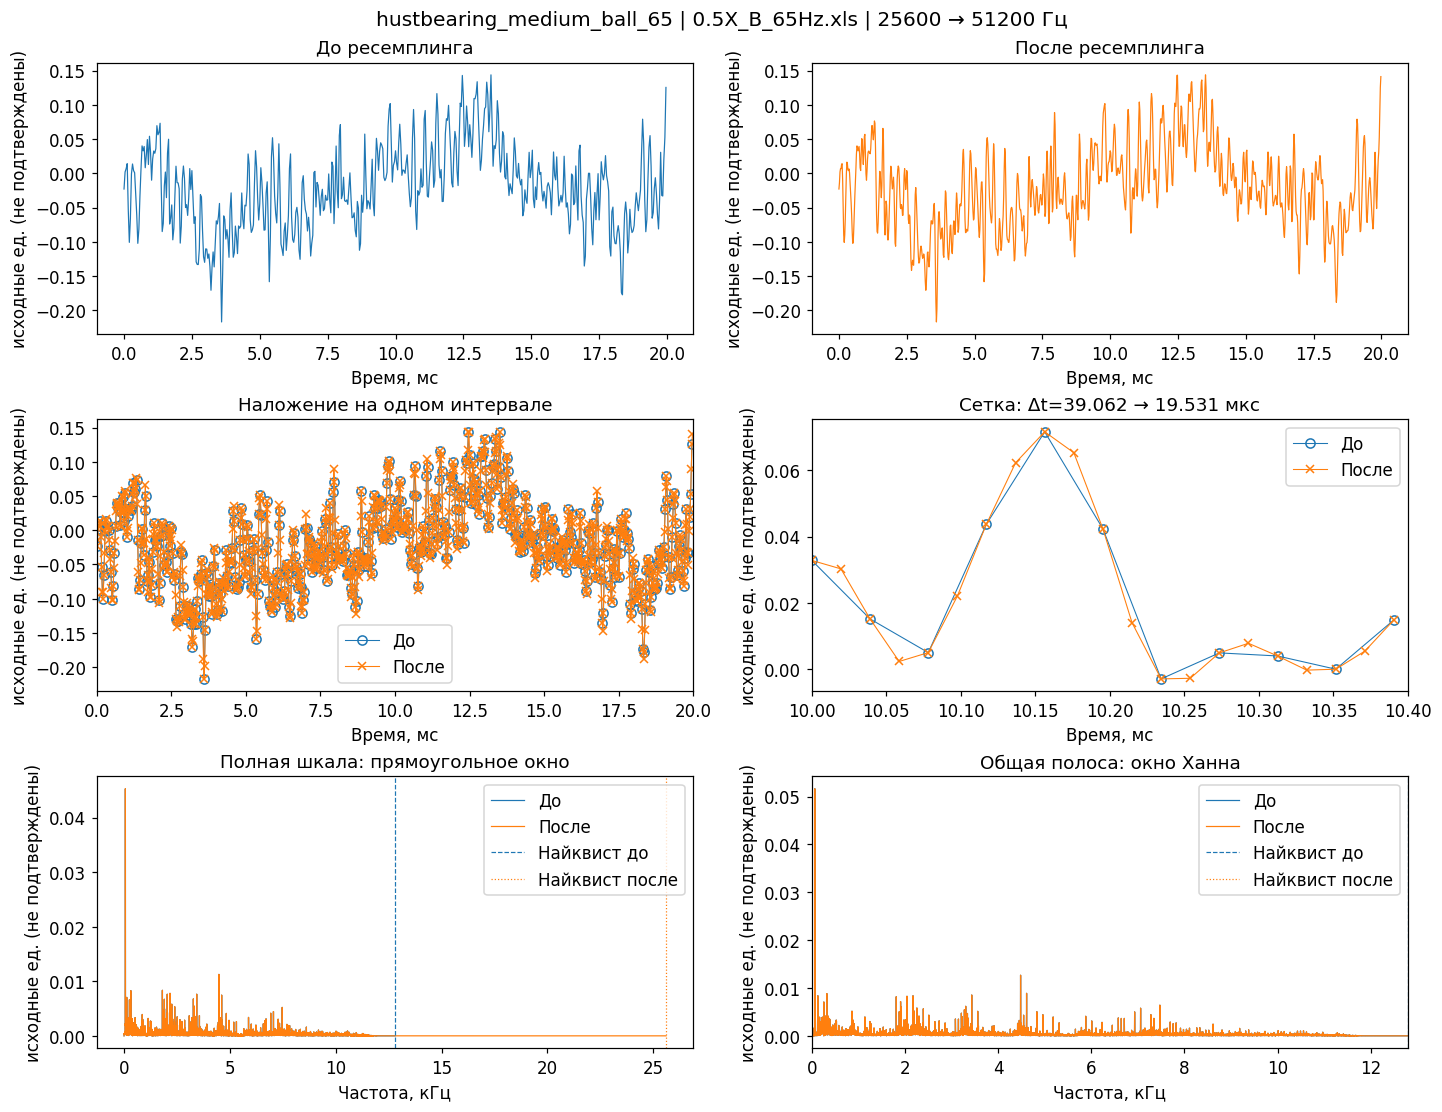

,До,После
mean,-0.017459,-0.017459
rms_raw,0.062393,0.062393
std_centered,0.059900,0.059900
max_abs,0.263116,0.267895
crest_raw,4.217096,4.293688
crest_centered,4.101107,4.180886
excess,-0.136960,-0.136826


In [11]:
examples = ["cwru_outer", "pu_K001", "mfpt_baseline_1", "jnu_normal", "hustbearing_medium_ball_65"]
explanations = {
    "cwru_outer": "Повышение 12 → 51,2 кГц: сетка плотнее, но информация выше 6 кГц не появляется.",
    "pu_K001": "Понижение 64 → 51,2 кГц: коэффициенты выше 25,6 кГц удаляются; RMS может уменьшиться.",
    "mfpt_baseline_1": "Понижение 97,656 → 51,2 кГц: удаляется верхняя часть исходной полосы до 48,828 кГц.",
    "jnu_normal": "Повышение 50 → 51,2 кГц невелико: положения отсчётов меняются, измеренная полоса не расширяется.",
    "hustbearing_medium_ball_65": "Повышение 25,6 → 51,2 кГц вдвое: интерполяция между исходными отсчётами; информационная граница 12,8 кГц.",
}
for record_id in examples:
    original, converted, g = computed[record_id]
    native_unit = by_id[record_id]["signal_unit"] or "исходные ед. (не подтверждены)"
    tx = np.arange(len(original))/g["fs_in"]
    ty = np.arange(len(converted))/g["fs_out"]
    fig, axes = plt.subplots(3, 2, figsize=(13, 10), layout="constrained")
    fig.suptitle(f"{record_id} | {by_id[record_id]['source_filename']} | {g['fs_in']} → {g['fs_out']} Гц")
    lo = min(original[tx < .02].min(), converted[ty < .02].min())
    hi = max(original[tx < .02].max(), converted[ty < .02].max())
    margin = .05*(hi-lo)
    for ax, times, values, title in [
        (axes[0, 0], tx, original, "До ресемплинга"),
        (axes[0, 1], ty, converted, "После ресемплинга"),
    ]:
        mask = times < .02
        ax.plot(times[mask]*1000, values[mask], lw=.8, color="tab:blue" if title.startswith("До") else "tab:orange")
        ax.set(title=title, xlabel="Время, мс", ylabel=native_unit, ylim=(lo-margin, hi+margin))
    # На 0,4 мс видно около 5–40 исходных точек в зависимости от fs.
    for ax, limits, title in [
        (axes[1, 0], (0, .02), "Наложение на одном интервале"),
        (axes[1, 1], (.01, .0104), f"Сетка: Δt={1e6/g['fs_in']:.3f} → {1e6/g['fs_out']:.3f} мкс"),
    ]:
        for times, values, label in [(tx, original, "До"), (ty, converted, "После")]:
            mask = (times >= limits[0]) & (times < limits[1])
            ax.plot(times[mask]*1000, values[mask], linestyle="-", marker="o" if label=="До" else "x", color="tab:blue" if label=="До" else "tab:orange", lw=.7, ms=6 if label=="До" else 5, markerfacecolor="none", label=label)
        ax.set(title=title, xlabel="Время, мс", ylabel=native_unit, xlim=(limits[0]*1000, limits[1]*1000))
        ax.legend()
    for ax, window, title in [
        (axes[2, 0], "rectangular", "Полная шкала: прямоугольное окно"),
        (axes[2, 1], "hann", "Общая полоса: окно Ханна"),
    ]:
        for values, rate, label in [(original, g["fs_in"], "До"), (converted, g["fs_out"], "После")]:
            f, amplitude = amplitude_spectrum(values, rate, window)
            ax.plot(f/1000, amplitude, lw=.8, color="tab:blue" if label=="До" else "tab:orange", label=label)
        common = min(g["fs_in"], g["fs_out"])/2
        ax.axvline(g["fs_in"]/2000, color="tab:blue", ls="--", lw=.8, label="Найквист до")
        ax.axvline(g["fs_out"]/2000, color="tab:orange", ls=":", lw=.8, label="Найквист после")
        if window == "rectangular" and g["fs_out"] < g["fs_in"]:
            ax.axvspan(g["fs_out"]/2000, g["fs_in"]/2000, color="grey", alpha=.18, label="Удаляемая полоса")
        ax.set(title=title, xlabel="Частота, кГц", ylabel=native_unit)
        if window == "hann": ax.set_xlim(0, common/1000)
        ax.legend()
    show(fig)
    print(explanations[record_id])
    display(pd.DataFrame({"До": statistics(original), "После": statistics(converted)}))


## 12. Удаляемая верхняя полоса
При понижении энергия выше нового Найквиста удаляется. В таблице — доля от входного среднего квадрата, рассчитанная общей функцией через Парсеваля. Это не доля «шума»: физическая природа удаляемых компонент здесь не установлена.

,id,removed_energy_percent,before_rms_raw,after_rms_raw
4,pu_K001,16.159915,0.401837,0.367939
5,pu_KA01,0.934082,0.539227,0.536702
10,mfpt_baseline_1,19.673042,0.887210,0.795165
12,mfpt_OuterRaceFault_1,29.785991,0.720834,0.604014


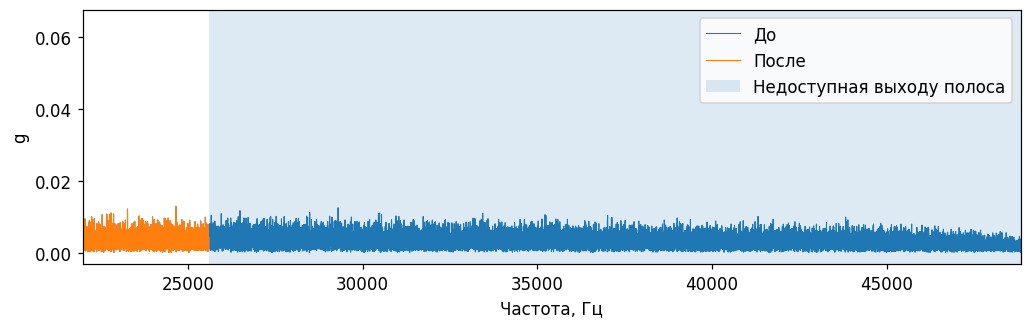

In [12]:
down = summary[summary.fs_in > 51200].copy()
down["removed_energy_percent"] = 100*down.input_energy_above_output_nyquist_fraction
display(down[["id", "removed_energy_percent", "before_rms_raw", "after_rms_raw"]])
original, converted, g = computed["mfpt_baseline_1"]
fig, ax = plt.subplots(figsize=(11, 3))
for z, rate, label in [(original, g["fs_in"], "До"), (converted, g["fs_out"], "После")]:
    f, a = amplitude_spectrum(z, rate, "rectangular")
    ax.plot(f, a, lw=.7, label=label)
ax.axvspan(25600, g["fs_in"]/2, alpha=.15, label="Недоступная выходу полоса")
ax.set(xlabel="Частота, Гц", ylabel="g", xlim=(22000, g["fs_in"]/2))
ax.legend()
show(fig)

## 13. Полный HUSTbearing и края
Полный X и секундный X перекрываются; X/Y/Z относятся к одному опыту. Округлённые временные метки файла не используются для оценки fs по первой разности. Сетка строится по документированным 25600 Гц. Периодическое продолжение соединяет конец с началом; разрыв может вызвать колебания интерполянта.

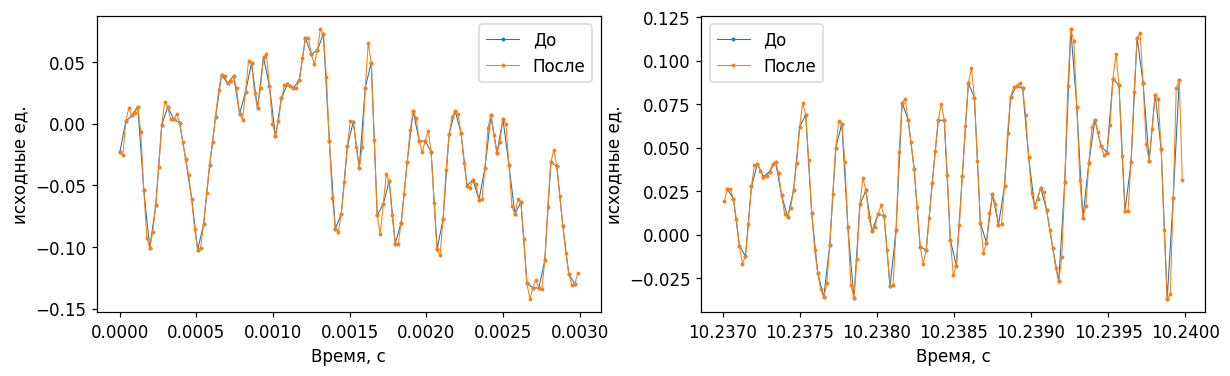

,id,N,M,T,input_endpoint_jump,output_endpoint_jump
13,hustbearing_medium_ball_65,25600,51200,1.00,-0.009582,-0.008145
14,hustbearing_medium_ball_65_full_X,262144,524288,10.24,-0.111934,-0.054553
15,hustbearing_medium_ball_65_full_Y,262144,524288,10.24,-0.061778,-0.029115
16,hustbearing_medium_ball_65_full_Z,262144,524288,10.24,-0.015414,-0.015638


In [13]:
edge_id = "hustbearing_medium_ball_65_full_X"
original, converted, g = computed[edge_id]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for ax, (start, stop) in zip(axes, [(0, .003), (g["duration"]-.003, g["duration"])]):
    for z, rate, label in [(original, g["fs_in"], "До"), (converted, g["fs_out"], "После")]:
        times = np.arange(len(z))/rate
        mask = (times >= start) & (times < stop)
        ax.plot(times[mask], z[mask], ".-", ms=3, lw=.7, label=label)
    ax.set(xlabel="Время, с", ylabel="исходные ед.")
    ax.legend()
show(fig)
display(summary.loc[summary.id.str.contains("hustbearing"), ["id", "N", "M", "T", "input_endpoint_jump", "output_endpoint_jump"]])

Разность крайних отсчётов — индикатор стыка, а не измеренная ошибка восстановления. Без непрерывного эталона нельзя доказать, что каждое новое колебание является артефактом. Здесь не исправляем края и не разбиваем запись на независимо обрабатываемые блоки.

## Количественное сравнение пяти примеров

Для любого ненулевого исходного показателя $q$ изменение определяется как $100(q_{после}/q_{до}-1)$, в процентах. При нулевом знаменателе выводим NaN, а не бесконечность. RMS включает постоянную составляющую; СКО — нет.

**Энергия:** для ненормированной ДПФ $X_k$ вещественного ряда берём веса $w_0=1$, $w_{N/2}=1$ при чётном $N$, прочие положительные бины имеют вес 2. По Парсевалю $\mathrm{mean}(x^2)=\sum_k w_k|X_k|^2/N^2$. Доля выше нового Найквиста — отношение этой суммы только по $f_k>f_s'/2$ к полной сумме. DC включён в знаменатель, но не в числитель. Граничный бин ровно на новом Найквисте исключён из числителя. Поэтому это доля **выше границы**, а не точный процент изменения RMS²: граничный бин обрабатывается особо. Для повышения выводим NaN («не применяется»).

**Общая полоса:** $a_k=\mathrm{rFFT}(x)_k/N$, $b_k=\mathrm{rFFT}(y)_k/M$. Поскольку длительности совпадают, частоты $k/T$ совпадают. Используем внутренние бины $0\le k<\lfloor\min(N,M)/2\rfloor$, исключая особый граничный бин, и метрику $\epsilon=\max_k|a_k-b_k|/\max(\max_n|x_n|,10^{-12})$. Она сравнивает и амплитуды, и фазы, без деления на почти нулевые отдельные бины. Нормировка делает её безразмерной; порог 1e−12 в знаменателе выражен в исходных единицах.

Для количественных оценок окно не применяется, среднее не удаляется. Спектры с Ханном служат иллюстрацией; они не используются для энергии и этой метрики. Доля энергии не является процентом потерянной диагностической информации.


In [14]:
def percent_change(before, after):
    return 100*(after/before-1) if before != 0 else np.nan

comparison_rows = []
for record_id in examples:
    a, b, g = computed[record_id]
    sa, sb = statistics(a), statistics(b)
    n0, n1 = len(a), len(b)
    X, Y = np.fft.rfft(a), np.fft.rfft(b)
    weights = np.full(len(X), 2.)
    weights[0] = 1.
    if n0 % 2 == 0: weights[-1] = 1.
    energy = weights*np.abs(X)**2/n0**2
    np.testing.assert_allclose(energy.sum(), np.mean(a*a), rtol=1e-12, atol=1e-14)
    frequencies = np.fft.rfftfreq(n0, 1/g["fs_in"])
    k = min(n0, n1)//2
    np.testing.assert_allclose(frequencies[:k], np.fft.rfftfreq(n1, 1/g["fs_out"])[:k], rtol=1e-12, atol=1e-10)
    epsilon = np.max(np.abs(X[:k]/n0-Y[:k]/n1))/max(np.max(np.abs(a)), 1e-12)
    removed = 100*energy[frequencies > g["fs_out"]/2].sum()/energy.sum() if g["fs_out"] < g["fs_in"] and energy.sum() else np.nan
    entry = {"dataset": by_id[record_id]["dataset"], "id": record_id,
             "units": by_id[record_id]["signal_unit"] or "не подтверждены", "fs_Hz": g["fs_in"],
             "target_Hz": g["fs_out"], "N": n0, "M": n1, "samples_change_%": percent_change(n0,n1),
             "energy_above_new_Nyquist_%": removed, "common_spectrum_error": epsilon}
    for metric in ["rms_raw", "std_centered", "max_abs"]:
        entry[metric+"_before"] = sa[metric]
        entry[metric+"_after"] = sb[metric]
        entry[metric+"_change_%"] = percent_change(sa[metric],sb[metric])
    comparison_rows.append(entry)
comparison = pd.DataFrame(comparison_rows)
with pd.option_context("display.max_columns", None):
    display(comparison)
# Компактные представления той же таблицы, чтобы не читать широкую таблицу с прокруткой.
display(comparison[["id", "fs_Hz", "target_Hz", "N", "M", "samples_change_%", "energy_above_new_Nyquist_%", "common_spectrum_error"]])
display(comparison[["id", "units"]+[c for c in comparison if c.startswith(("rms_raw", "std_centered", "max_abs"))]])
assert (comparison.common_spectrum_error < 1e-10).all()


,dataset,id,units,fs_Hz,target_Hz,N,M,samples_change_%,energy_above_new_Nyquist_%,common_spectrum_error,rms_raw_before,rms_raw_after,rms_raw_change_%,std_centered_before,std_centered_after,std_centered_change_%,max_abs_before,max_abs_after,max_abs_change_%
0,CWRU,cwru_outer,g,12000,51200,12000,51200,326.666667,NaN,6.185256e-18,0.676408,0.676408,-1.256464e-06,0.675567,0.675567,-1.259594e-06,3.547583,3.526876,-0.583694
1,Paderborn,pu_K001,не подтверждены,64000,51200,64000,51200,-20.000000,16.159915,7.048156e-19,0.401837,0.367939,-8.435762e+00,0.401419,0.367483,-8.454129e+00,4.162598,3.161583,-24.047847
2,MFPT,mfpt_baseline_1,g,97656,51200,97656,51200,-47.571066,19.673042,6.752721e-18,0.887210,0.795165,-1.037469e+01,0.876620,0.783331,-1.064186e+01,4.110280,3.179494,-22.645307
3,JNU,jnu_normal,не подтверждены,50000,51200,50000,51200,2.400000,NaN,2.765601e-18,0.089459,0.089458,-1.596105e-05,0.089450,0.089450,-1.596404e-05,1.254500,1.496815,19.315686
4,HUSTbearing-Huazhong,hustbearing_medium_ball_65,не подтверждены,25600,51200,25600,51200,100.000000,NaN,1.864782e-17,0.062393,0.062393,-1.311735e-08,0.059900,0.059900,-1.423175e-08,0.263116,0.267895,1.816221


,id,fs_Hz,target_Hz,N,M,samples_change_%,energy_above_new_Nyquist_%,common_spectrum_error
0,cwru_outer,12000,51200,12000,51200,326.666667,NaN,6.185256e-18
1,pu_K001,64000,51200,64000,51200,-20.000000,16.159915,7.048156e-19
2,mfpt_baseline_1,97656,51200,97656,51200,-47.571066,19.673042,6.752721e-18
3,jnu_normal,50000,51200,50000,51200,2.400000,NaN,2.765601e-18
4,hustbearing_medium_ball_65,25600,51200,25600,51200,100.000000,NaN,1.864782e-17


,id,units,rms_raw_before,rms_raw_after,rms_raw_change_%,std_centered_before,std_centered_after,std_centered_change_%,max_abs_before,max_abs_after,max_abs_change_%
0,cwru_outer,g,0.676408,0.676408,-1.256464e-06,0.675567,0.675567,-1.259594e-06,3.547583,3.526876,-0.583694
1,pu_K001,не подтверждены,0.401837,0.367939,-8.435762e+00,0.401419,0.367483,-8.454129e+00,4.162598,3.161583,-24.047847
2,mfpt_baseline_1,g,0.887210,0.795165,-1.037469e+01,0.876620,0.783331,-1.064186e+01,4.110280,3.179494,-22.645307
3,jnu_normal,не подтверждены,0.089459,0.089458,-1.596105e-05,0.089450,0.089450,-1.596404e-05,1.254500,1.496815,19.315686
4,hustbearing_medium_ball_65,не подтверждены,0.062393,0.062393,-1.311735e-08,0.059900,0.059900,-1.423175e-08,0.263116,0.267895,1.816221


## Что сохранилось, что изменилось и почему?

При повышении CWRU и HUSTbearing новые точки вычислены из прежнего периодического представления. Плотность выросла, информационная полоса — нет. Максимум может измениться, поскольку новая сетка иначе попадает на вершины интерполянта. При понижении MFPT и Paderborn верхняя полоса удаляется; это способно уменьшить RMS и изменить пики. Значимость удалённых компонент для диагностики требует отдельного исследования, а не вывода из процента энергии. При переходе JNU 50→51,2 кГц изменение сетки невелико, поэтому наложение выглядит почти совпадающим. Совпадение в общей полосе ожидаемо для корректного FFT-метода, а не означает, что преобразование не произошло.

Следующая ячейка формулирует конкретные выводы из только что рассчитанной таблицы.

Важно для JNU: близость частот не гарантирует близости максимума всей записи. В рассчитанной таблице максимум изменился заметно, хотя RMS почти сохранился. График первых 20 мс не описывает каждый пик полного секундного ряда. Новая сетка и периодическая интерполяция могут менять экстремумы; без непрерывного эталона нельзя считать новый пик новым физическим измерением. Малые изменения RMS при повышении также возможны из-за особой обработки исходного бина Найквиста.


In [15]:
for _, q in comparison.iterrows():
    mode = "понижение" if q.fs_Hz > q.target_Hz else "повышение"
    print(f"{q['id']}: {mode}; число отсчётов {q['samples_change_%']:+.3f}%; "
          f"RMS {q['rms_raw_change_%']:+.6f}%; СКО {q['std_centered_change_%']:+.6f}%; "
          f"максимум {q['max_abs_change_%']:+.4f}%; ошибка общей полосы {q.common_spectrum_error:.3e}.")
    if pd.notna(q['energy_above_new_Nyquist_%']):
        print(f"  Выше нового Найквиста находилось {q['energy_above_new_Nyquist_%']:.4f}% входного среднего квадрата; диагностический смысл этой доли не установлен.")


cwru_outer: повышение; число отсчётов +326.667%; RMS -0.000001%; СКО -0.000001%; максимум -0.5837%; ошибка общей полосы 6.185e-18.
pu_K001: понижение; число отсчётов -20.000%; RMS -8.435762%; СКО -8.454129%; максимум -24.0478%; ошибка общей полосы 7.048e-19.
  Выше нового Найквиста находилось 16.1599% входного среднего квадрата; диагностический смысл этой доли не установлен.
mfpt_baseline_1: понижение; число отсчётов -47.571%; RMS -10.374691%; СКО -10.641861%; максимум -22.6453%; ошибка общей полосы 6.753e-18.
  Выше нового Найквиста находилось 19.6730% входного среднего квадрата; диагностический смысл этой доли не установлен.
jnu_normal: повышение; число отсчётов +2.400%; RMS -0.000016%; СКО -0.000016%; максимум +19.3157%; ошибка общей полосы 2.766e-18.
hustbearing_medium_ball_65: повышение; число отсчётов +100.000%; RMS -0.000000%; СКО -0.000000%; максимум +1.8162%; ошибка общей полосы 1.865e-17.


### Научные ограничения

Ресемплинг сам по себе не улучшает качество измерений. Повышение fs не восстанавливает неизвестные высокочастотные компоненты. Понижение может удалить диагностически значимые составляющие. Совпадение осциллограмм не доказывает сохранность всех диагностических признаков; изменение пика не обязательно является ошибкой. Результаты пяти примеров нельзя автоматически переносить на все записи наборов. Оптимальность 51 200 Гц для диагностики здесь не установлена. Итоговая таблица 17 рядов ниже сохранена как отдельный результат.


## 14. Итоговая таблица всех 17 рядов
Все значения ниже вычислены в этом сеансе. Полный `summary` содержит также пик-факторы, эксцесс, ошибки и крайние значения.

In [16]:
display(summary[["id", "fs_in", "N", "M", "T", "passed", "before_rms_raw", "after_rms_raw", "before_std_centered", "after_std_centered", "before_max_abs", "after_max_abs", "common_complex_error"]])
assert len(summary) == 17 and summary.passed.all()
print("Максимальная ошибка общей полосы:", summary.common_complex_error.max())

Максимальная ошибка общей полосы: 1.8647816679285172e-17


,id,fs_in,N,M,T,passed,before_rms_raw,after_rms_raw,before_std_centered,after_std_centered,before_max_abs,after_max_abs,common_complex_error
0,cwru_normal,48000,48000,51200,1.00,True,0.073485,0.073485,0.072535,0.072535,0.286638,0.287983,1.353263e-17
1,cwru_inner,12000,12000,51200,1.00,True,0.289302,0.289302,0.288906,0.288906,1.584555,1.643653,4.895962e-18
2,cwru_ball,12000,12000,51200,1.00,True,0.138266,0.138266,0.137421,0.137421,0.525803,0.548076,9.331524e-18
3,cwru_outer,12000,12000,51200,1.00,True,0.676408,0.676408,0.675567,0.675567,3.547583,3.526876,6.185256e-18
4,pu_K001,64000,64000,51200,1.00,True,0.401837,0.367939,0.401419,0.367483,4.162598,3.161583,7.048156e-19
5,pu_KA01,64000,64000,51200,1.00,True,0.539227,0.536702,0.538954,0.536428,3.781128,3.789093,2.753641e-18
6,jnu_normal,50000,50000,51200,1.00,True,0.089459,0.089458,0.089450,0.089450,1.254500,1.496815,2.765601e-18
7,jnu_inner,50000,50000,51200,1.00,True,0.170301,0.170301,0.170220,0.170220,2.508200,4.924435,2.766483e-18
8,jnu_outer,50000,50000,51200,1.00,True,0.283963,0.283962,0.283945,0.283945,6.327900,6.547894,5.651518e-19
9,jnu_ball,50000,50000,51200,1.00,True,0.204251,0.204251,0.204250,0.204250,6.327900,6.905734,9.884218e-19


## 15. Выводы и вопросы для самостоятельной проверки

- Проверено сохранение длительности, среднего и внутренней общей спектральной полосы; сохранённые результаты 0.2.0 воспроизведены.
- Повышение частоты делает сетку плотнее, но не расширяет измеренную информационную полосу. Для CWRU 12 кГц требование фильтра до 10 кГц остаётся несогласованным.
- Понижение Paderborn и MFPT удаляет верхнюю полосу. Изменение RMS отражает это, а не само по себе неисправность кода.
- Режимы, единицы и независимость образцов не становятся одинаковыми после ресемплинга. По этим фрагментам нельзя делать новые диагностические выводы.

**Попробуйте:** выберите `cwru_normal`, затем `pu_KA01`; сравните изменение максимума и RMS. Объясните, почему они не обязаны изменяться одинаково. Рассмотрите край полной HUST-записи и её секундного фрагмента: периодические продолжения различаются.

Нормировка, Баттерворт, объединение и обучение не выполнялись. Следующий этап требует отдельного решения.

Источник API: https://docs.scipy.org/doc/scipy-1.17.0/reference/generated/scipy.signal.resample.html . Происхождение записей — `configs/records.json`, аудит и учебные материалы — `legacy/stage1/`.